## 1. Import Libraries and Load Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("aiml_training_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (230, 3)


,text,intent,confidence
0,Where is my order?,order_status,0.77
1,When will my package arrive?,order_status,0.91
2,Track my order please,order_status,0.75
3,Order tracking update needed,order_status,0.83
4,Has my order shipped yet?,order_status,0.90


## 2. Dataset Information and Descriptive Statistics

In [3]:
print("Dataset Information")
print("-------------------")

df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDescriptive Statistics:")
display(df.describe(include="all"))

Dataset Information
-------------------
<class 'pandas.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   text        230 non-null    str    
 1   intent      230 non-null    str    
 2   confidence  230 non-null    float64
dtypes: float64(1), str(2)
memory usage: 5.5 KB

Missing Values:


text          0
intent        0
confidence    0
dtype: int64


Descriptive Statistics:


,text,intent,confidence
count,230,230,230.000000
unique,230,6,NaN
top,Where is my order?,return_request,NaN
freq,1,46,NaN
mean,NaN,NaN,0.842217
std,NaN,NaN,0.084975
min,NaN,NaN,0.700000
25%,NaN,NaN,0.770000
50%,NaN,NaN,0.850000
75%,NaN,NaN,0.910000


## 3. Data Types, Missing Values, and Duplicate Check

In [4]:
print("Data Types:")
display(df.dtypes)

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nMissing Values:")
display(df.isnull().sum())

Data Types:


text              str
intent            str
confidence    float64
dtype: object


Duplicate Rows:
0

Missing Values:


text          0
intent        0
confidence    0
dtype: int64

## 4. Distribution of Confidence Scores

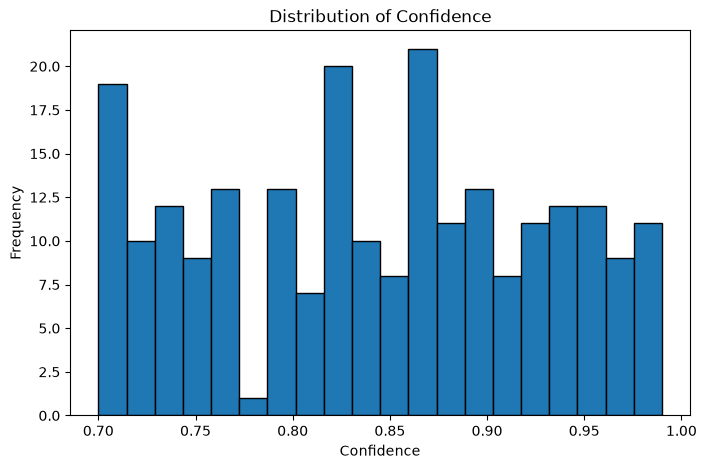

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["confidence"], bins=20, edgecolor="black")

plt.xlabel("Confidence")
plt.ylabel("Frequency")
plt.title("Distribution of Confidence")
plt.show()

## 5. Distribution of Intents

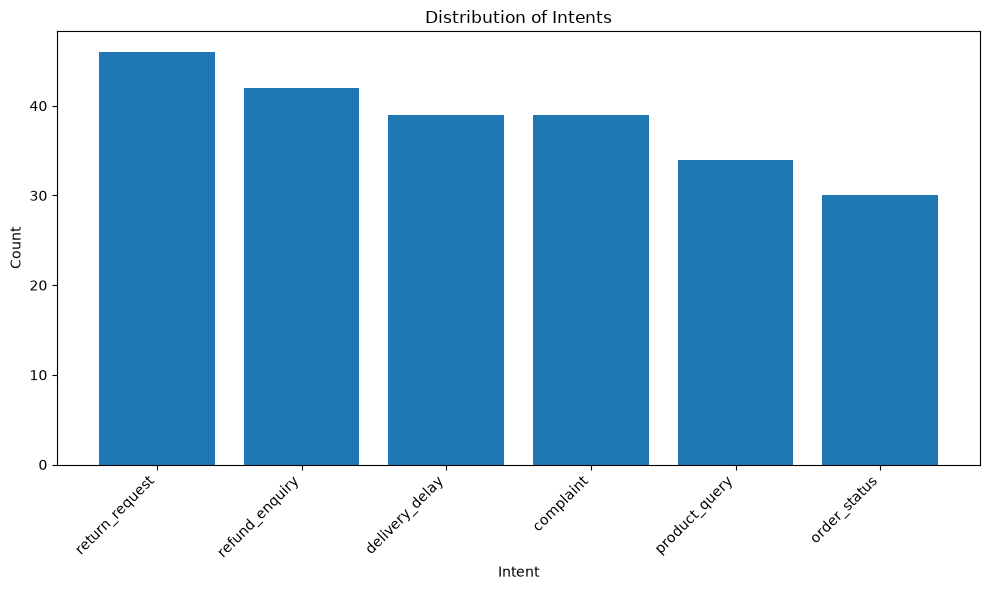

In [6]:
intent_counts = df["intent"].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(intent_counts.index, intent_counts.values)

plt.xlabel("Intent")
plt.ylabel("Count")
plt.title("Distribution of Intents")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## 6. Average Confidence by Intent

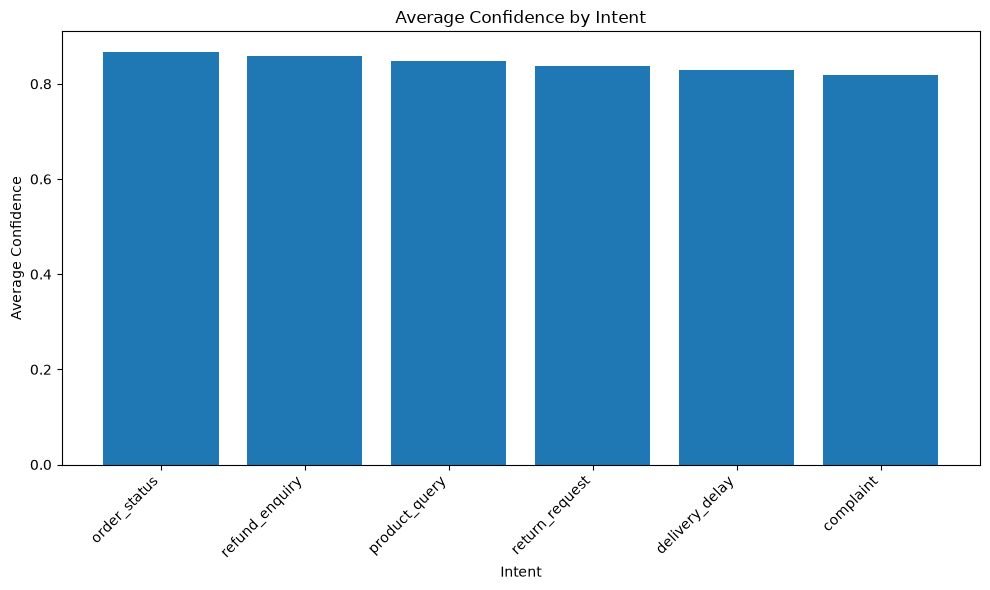

In [7]:
intent_confidence = (
    df.groupby("intent")["confidence"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(intent_confidence.index, intent_confidence.values)

plt.xlabel("Intent")
plt.ylabel("Average Confidence")
plt.title("Average Confidence by Intent")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [8]:
print("Average Confidence by Intent")
print("----------------------------")
display(intent_confidence.to_frame(name="Average Confidence").round(4))

Average Confidence by Intent
----------------------------


,Average Confidence
intent,
order_status,0.8670
refund_enquiry,0.8583
product_query,0.8488
return_request,0.8370
delivery_delay,0.8290
complaint,0.8195


In [9]:
print("Most Frequent Intents")
print("---------------------")
display(df["intent"].value_counts().head())

print("\nLeast Frequent Intents")
print("----------------------")
display(df["intent"].value_counts().tail())

Most Frequent Intents
---------------------


intent
return_request    46
refund_enquiry    42
delivery_delay    39
complaint         39
product_query     34
Name: count, dtype: int64


Least Frequent Intents
----------------------


intent
refund_enquiry    42
delivery_delay    39
complaint         39
product_query     34
order_status      30
Name: count, dtype: int64

/tmp/ipykernel_1872/843794301.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["confidence"], vert=True)


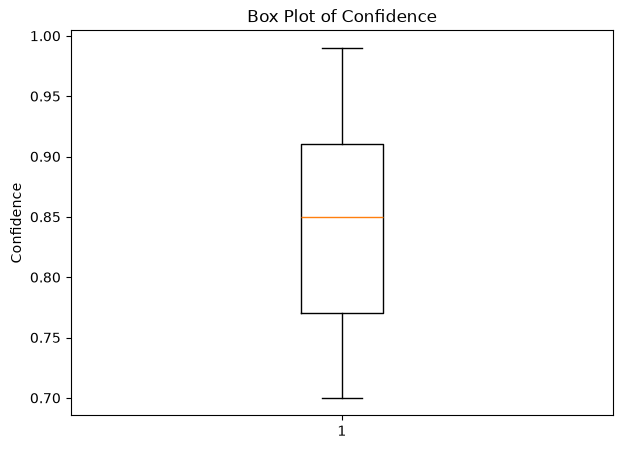

In [10]:
plt.figure(figsize=(7, 5))

plt.boxplot(df["confidence"], vert=True)

plt.ylabel("Confidence")
plt.title("Box Plot of Confidence")

plt.show()

In [11]:
print("EDA Summary")
print("-----------")

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"Number of unique intents: {df['intent'].nunique()}")
print(f"Average confidence: {df['confidence'].mean():.4f}")
print(f"Minimum confidence: {df['confidence'].min():.4f}")
print(f"Maximum confidence: {df['confidence'].max():.4f}")

EDA Summary
-----------
Number of rows: 230
Number of columns: 3
Number of unique intents: 6
Average confidence: 0.8422
Minimum confidence: 0.7000
Maximum confidence: 0.9900


## Conclusion

The dataset was explored using descriptive statistics, data-type inspection, missing-value and duplicate checks, and visualizations. The distribution of confidence scores and intents was analyzed, along with average confidence across intents. A box plot was also used to examine the spread and possible outliers in confidence values.